In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
X = pd.read_csv("values.csv")
y = pd.read_csv("labels.csv")
print(X.shape)
print(y.shape)

(180, 14)
(180, 2)


In [5]:
df = pd.concat([X, y], axis=1)
df.head()

,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,patient_id,heart_disease_present
0,0z64un,1,normal,128,2,0,0,2,308,0.0,1,45,170,0,0z64un,0
1,ryoo3j,2,normal,110,3,0,0,0,214,1.6,0,54,158,0,ryoo3j,0
2,yt1s1x,1,normal,125,4,3,0,2,304,0.0,1,77,162,1,yt1s1x,1
3,l2xjde,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0,l2xjde,1
4,oyt4ek,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0,oyt4ek,0


In [7]:
df.shape

(180, 16)

In [9]:
df.drop(['patient_id'],axis=1,inplace=True)

In [11]:
df.shape

(180, 14)

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 14 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   slope_of_peak_exercise_st_segment     180 non-null    int64  
 1   thal                                  180 non-null    object 
 2   resting_blood_pressure                180 non-null    int64  
 3   chest_pain_type                       180 non-null    int64  
 4   num_major_vessels                     180 non-null    int64  
 5   fasting_blood_sugar_gt_120_mg_per_dl  180 non-null    int64  
 6   resting_ekg_results                   180 non-null    int64  
 7   serum_cholesterol_mg_per_dl           180 non-null    int64  
 8   oldpeak_eq_st_depression              180 non-null    float64
 9   sex                                   180 non-null    int64  
 10  age                                   180 non-null    int64  
 11  max_heart_rate_achi

In [15]:
df.describe()

,slope_of_peak_exercise_st_segment,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
count,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000
mean,1.550000,131.311111,3.155556,0.694444,0.161111,1.050000,249.211111,1.010000,0.688889,54.811111,149.483333,0.316667,0.444444
std,0.618838,17.010443,0.938454,0.969347,0.368659,0.998742,52.717969,1.121357,0.464239,9.334737,22.063513,0.466474,0.498290
min,1.000000,94.000000,1.000000,0.000000,0.000000,0.000000,126.000000,0.000000,0.000000,29.000000,96.000000,0.000000,0.000000
25%,1.000000,120.000000,3.000000,0.000000,0.000000,0.000000,213.750000,0.000000,0.000000,48.000000,132.000000,0.000000,0.000000
50%,1.000000,130.000000,3.000000,0.000000,0.000000,2.000000,245.500000,0.800000,1.000000,55.000000,152.000000,0.000000,0.000000
75%,2.000000,140.000000,4.000000,1.000000,0.000000,2.000000,281.250000,1.600000,1.000000,62.000000,166.250000,1.000000,1.000000
max,3.000000,180.000000,4.000000,3.000000,1.000000,2.000000,564.000000,6.200000,1.000000,77.000000,202.000000,1.000000,1.000000


In [17]:
df.isnull().sum()

slope_of_peak_exercise_st_segment       0
thal                                    0
resting_blood_pressure                  0
chest_pain_type                         0
num_major_vessels                       0
fasting_blood_sugar_gt_120_mg_per_dl    0
resting_ekg_results                     0
serum_cholesterol_mg_per_dl             0
oldpeak_eq_st_depression                0
sex                                     0
age                                     0
max_heart_rate_achieved                 0
exercise_induced_angina                 0
heart_disease_present                   0
dtype: int64

In [19]:
X = df.drop("heart_disease_present", axis=1)
y = df["heart_disease_present"]

In [21]:
print(X.shape)
y.shape

(180, 13)


(180,)

In [23]:
y.shape

(180,)

# Heart Disease Prediction — A-Grade Upgrade

## Project objective
Build a robust classification workflow to identify patients at higher risk of heart disease. The upgraded workflow focuses on **clinically meaningful evaluation**, leakage-safe preprocessing, categorical EDA, justified outlier handling, multicollinearity control, stratified cross-validation, hyperparameter tuning, threshold selection, and model interpretation.

**Important:** this notebook supports decision-making research and is not a clinical diagnosis tool.

## Quality checklist addressed
- Explain the insight behind important graphs, not just display them.
- Cover categorical as well as numerical EDA.
- Diagnose outliers without blindly deleting legitimate patients.
- Quantify any row removal (none is performed by default).
- Address multicollinearity using a training-only correlation filter.
- Keep imputation, encoding and scaling inside pipelines to prevent leakage.
- Tune models with stratified cross-validation rather than arbitrary defaults.
- Compare appropriate regularized and non-linear classifiers.
- Evaluate with recall, precision, F1, ROC-AUC and PR-AUC—not accuracy alone.
- Optimize the decision threshold on validation data only.
- Investigate model weaknesses through confusion matrices and error counts.
- Keep conclusions dynamic and based on the actual executed results.

In [29]:
X = df.drop("heart_disease_present", axis=1).copy()
y = df["heart_disease_present"].copy()

print("Features:", X.shape)
print("Target distribution:")
print(y.value_counts(dropna=False))
print("\nTarget proportions:")
print(y.value_counts(normalize=True).rename("proportion"))

Features: (180, 13)
Target distribution:
heart_disease_present
0    100
1     80
Name: count, dtype: int64

Target proportions:
heart_disease_present
0    0.555556
1    0.444444
Name: proportion, dtype: float64


## 1. Target distribution
A classification project should first establish how common the positive class is. Accuracy can be misleading when classes are uneven, so the positive-class rate is used to frame later metrics.

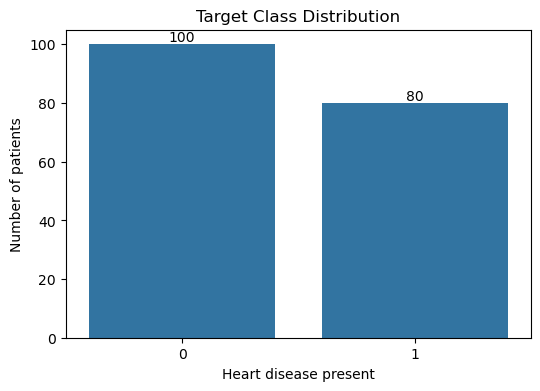

In [70]:
target_counts = y.value_counts().sort_index()
plt.figure(figsize=(6,4))
ax = sns.barplot(x=target_counts.index.astype(str), y=target_counts.values)
plt.xlabel("Heart disease present")
plt.ylabel("Number of patients")
plt.title("Target Class Distribution")
for i, v in enumerate(target_counts.values):
    ax.text(i, v, str(v), ha="center", va="bottom")
plt.show()

minority_rate = target_counts.min() / target_counts.sum()

## 2. Missing values and data quality
Missing values are reported before modeling. They are **not imputed globally**; model-specific imputers are fitted only on training data inside pipelines.

In [35]:
missing = X.isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]
if missing.empty:
    print("No missing values found in the feature matrix.")
else:
    print(missing.to_string())

No missing values found in the feature matrix.


## 3. Outlier diagnosis — retain legitimate observations
Medical measurements can contain genuine extremes. The boxplots below are diagnostic only. No patient rows are deleted solely because a value falls outside the IQR.

                             feature  iqr_outlier_rate
                   num_major_vessels          0.077778
                     chest_pain_type          0.072222
              resting_blood_pressure          0.033333
            oldpeak_eq_st_depression          0.022222
         serum_cholesterol_mg_per_dl          0.011111
   slope_of_peak_exercise_st_segment          0.000000
fasting_blood_sugar_gt_120_mg_per_dl          0.000000
                 resting_ekg_results          0.000000
                                 sex          0.000000
                                 age          0.000000
             max_heart_rate_achieved          0.000000
             exercise_induced_angina          0.000000


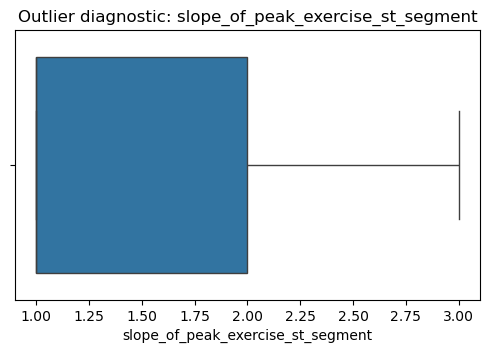

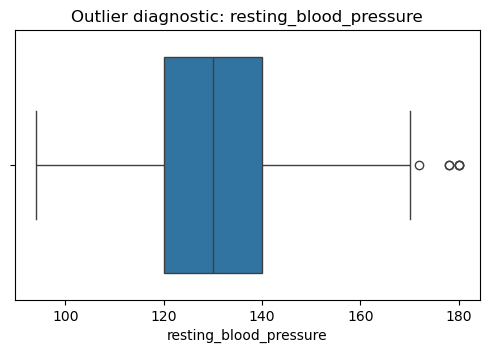

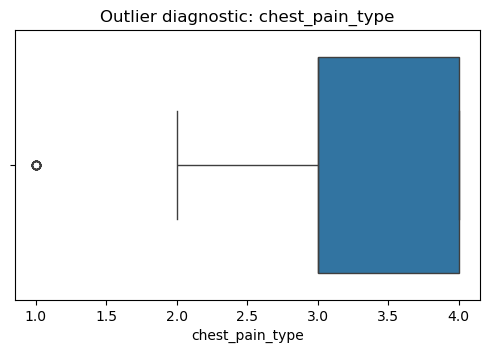

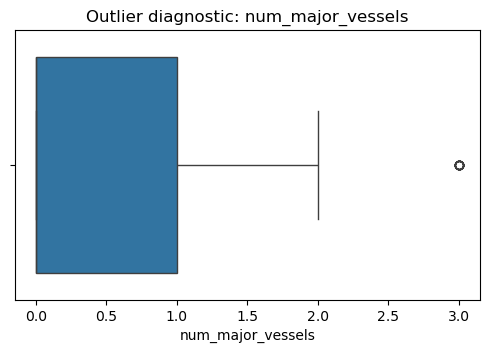

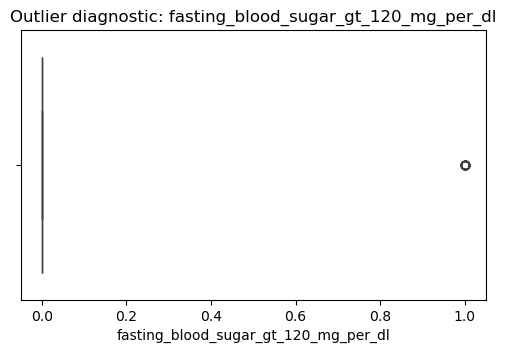

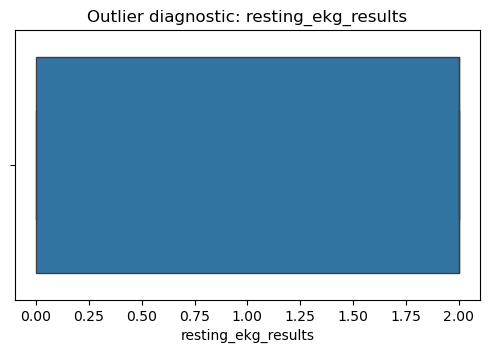

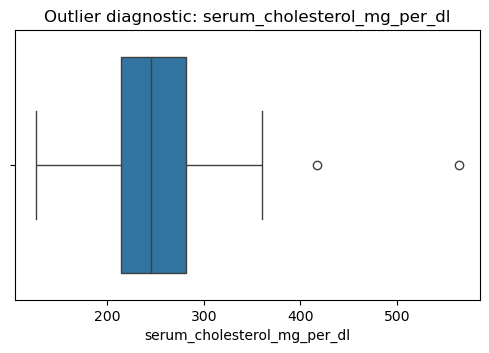

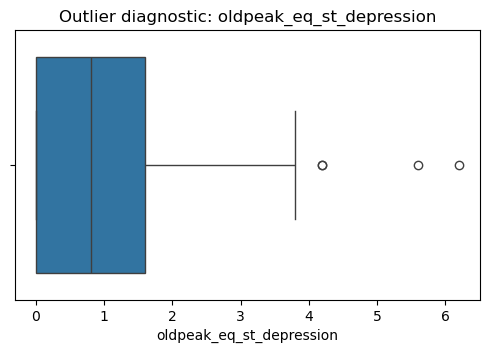

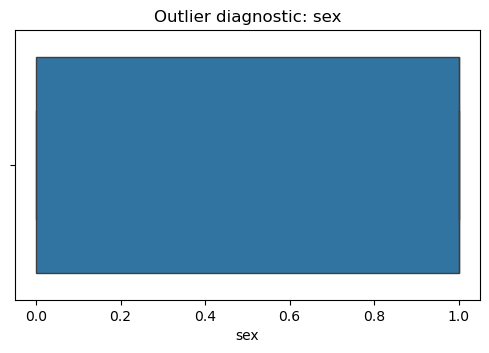

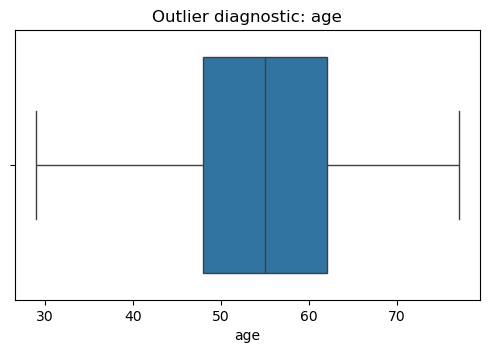

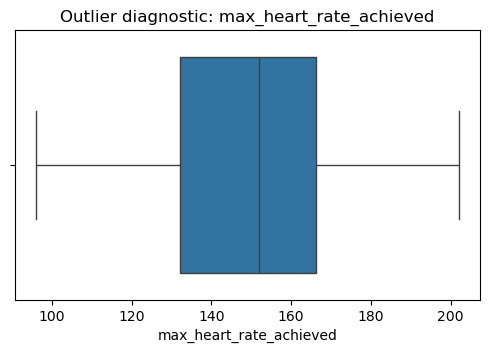

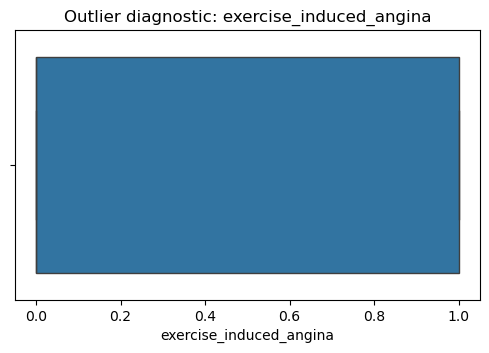

In [72]:
numeric_cols = X.select_dtypes(include=np.number).columns
outlier_rows = []
for col in numeric_cols:
    q1, q3 = X[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    if pd.isna(iqr) or iqr == 0:
        rate = 0.0
    else:
        mask = (X[col] < q1 - 1.5*iqr) | (X[col] > q3 + 1.5*iqr)
        rate = mask.mean()
    outlier_rows.append((col, rate))
outlier_summary = pd.DataFrame(outlier_rows, columns=["feature","iqr_outlier_rate"]).sort_values("iqr_outlier_rate", ascending=False)
print(outlier_summary.to_string(index=False))

for col in numeric_cols:
    plt.figure(figsize=(6,3.5))
    sns.boxplot(x=X[col])
    plt.title(f"Outlier diagnostic: {col}")
    plt.show()


## 4. Numerical EDA by target
Comparing distributions by outcome helps identify variables that may separate the classes and highlights where a linear model may struggle.

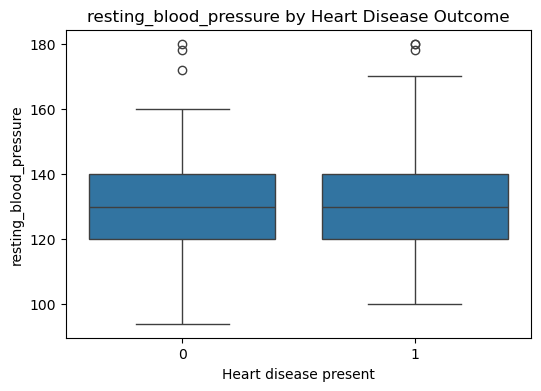

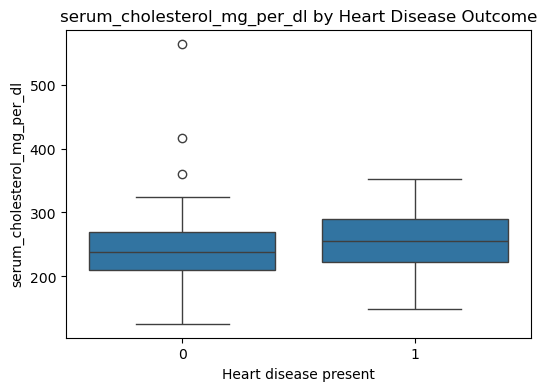

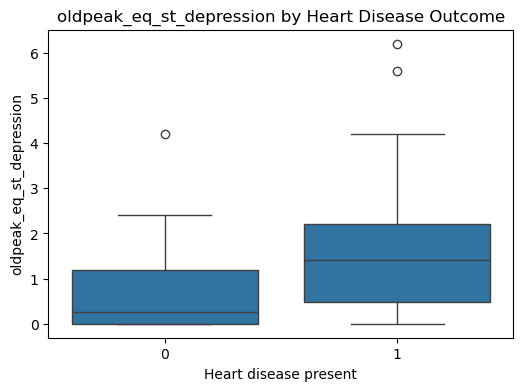

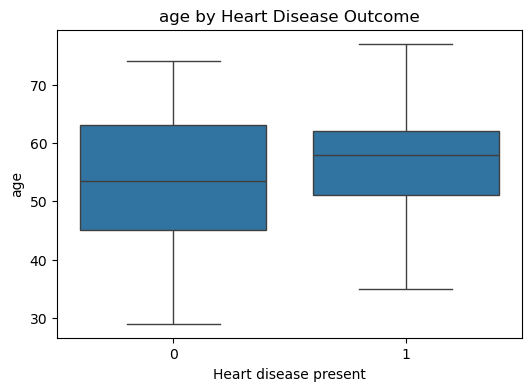

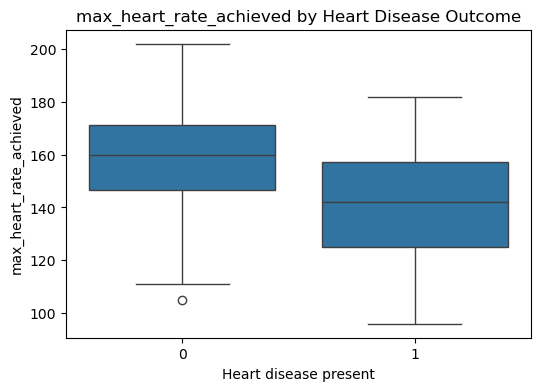

In [74]:
eda_numeric = [c for c in numeric_cols if X[c].nunique(dropna=True) > 5]
for col in eda_numeric:
    plt.figure(figsize=(6,4))
    sns.boxplot(data=pd.concat([X[[col]], y.rename("target")], axis=1), x="target", y=col)
    plt.title(f"{col} by Heart Disease Outcome")
    plt.xlabel("Heart disease present")
    plt.ylabel(col)
    plt.show()
    

## 5. Categorical EDA
Categorical variables are evaluated using both **frequency** and **disease rate within category**. Frequency alone does not tell us whether a category is associated with the outcome.

Categorical features: ['thal']

thal
                   count  disease_rate
thal                                  
reversible_defect     74      0.756757
fixed_defect           8      0.500000
normal                98      0.204082


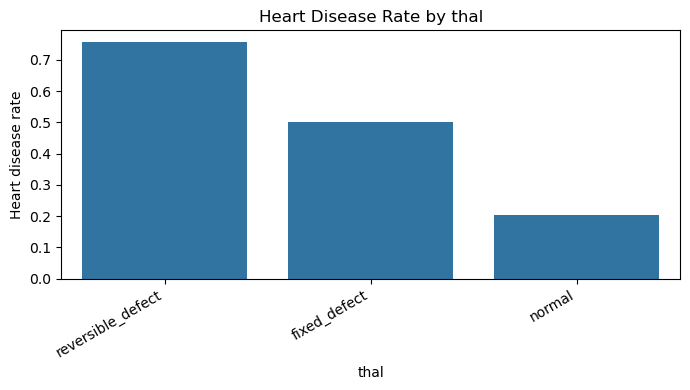

In [76]:
categorical_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
print("Categorical features:", categorical_cols)
for col in categorical_cols:
    rates = pd.DataFrame({
        "count": X[col].value_counts(dropna=False),
        "disease_rate": df.groupby(col, dropna=False)["heart_disease_present"].mean()
    }).sort_values("disease_rate", ascending=False)
    print(f"\n{col}")
    print(rates.to_string())
    plt.figure(figsize=(7,4))
    plot_df = rates.reset_index()
    sns.barplot(data=plot_df, x=col, y="disease_rate")
    plt.xticks(rotation=30, ha="right")
    plt.ylabel("Heart disease rate")
    plt.title(f"Heart Disease Rate by {col}")
    plt.tight_layout()
    plt.show()

## 6. Correlation and multicollinearity
Highly correlated predictors can make coefficient-based models unstable. Correlation screening is therefore performed **using training data only**, before fitting the final pipelines.

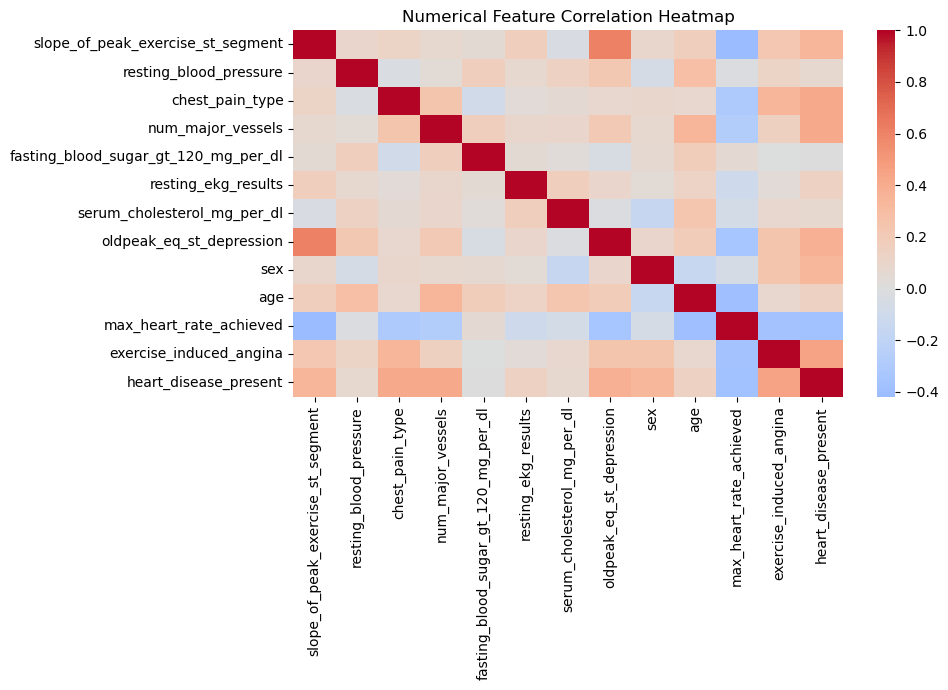

Top numerical relationships with target:
exercise_induced_angina              0.448647
num_major_vessels                    0.421519
chest_pain_type                      0.412829
oldpeak_eq_st_depression             0.382930
max_heart_rate_achieved              0.375352
slope_of_peak_exercise_st_segment    0.344224
sex                                  0.335421
resting_ekg_results                  0.145933
age                                  0.138255
serum_cholesterol_mg_per_dl          0.079775


In [78]:
plt.figure(figsize=(10,7))
num_corr = pd.concat([X[numeric_cols], y.rename("heart_disease_present")], axis=1).corr(numeric_only=True)
sns.heatmap(num_corr, cmap="coolwarm", center=0)
plt.title("Numerical Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

ranked_target_corr = num_corr["heart_disease_present"].drop("heart_disease_present").abs().sort_values(ascending=False)
print("Top numerical relationships with target:")
print(ranked_target_corr.head(10).to_string())


## 7. Leakage-safe train/validation/test split
The test set is held out until the final evaluation. A separate validation split is used only for threshold selection. All learned preprocessing parameters come from training data.

In [81]:
from sklearn.model_selection import train_test_split

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, test_size=0.25, random_state=42, stratify=y_train_full
)
print("Train:", X_train.shape, "Validation:", X_valid.shape, "Test:", X_test.shape)
print("Class rates:", y_train.mean(), y_valid.mean(), y_test.mean())

Train: (108, 13) Validation: (36, 13) Test: (36, 13)
Class rates: 0.4444444444444444 0.4444444444444444 0.4444444444444444


In [83]:

for frame_name, frame in [("train", X_train), ("validation", X_valid), ("test", X_test)]:
    if "patient_id" in frame.columns:
        frame.drop(columns=["patient_id"], inplace=True)

train_num = X_train.select_dtypes(include=np.number)
cor = train_num.corr().abs()
upper = cor.where(np.triu(np.ones(cor.shape), k=1).astype(bool))
high_corr_drop = [c for c in upper.columns if any(upper[c] > 0.95)]
print("Features removed for |training correlation| > 0.95:", high_corr_drop)
if high_corr_drop:
    X_train = X_train.drop(columns=high_corr_drop)
    X_valid = X_valid.drop(columns=high_corr_drop)
    X_test = X_test.drop(columns=high_corr_drop)
print("Data loss from multicollinearity handling: 0 patient rows; only redundant predictor columns are removed.")

Features removed for |training correlation| > 0.95: []
Data loss from multicollinearity handling: 0 patient rows; only redundant predictor columns are removed.


## 8. Preprocessing pipelines
Numeric values are median-imputed; categorical values are most-frequent imputed and one-hot encoded. Scaling is applied only for models that need it. Because these steps live inside pipelines, the validation/test data cannot influence fitted preprocessing.

In [86]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

numeric_scaled = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
numeric_unscaled = Pipeline([("imputer", SimpleImputer(strategy="median"))])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first"))
])

preprocess_scaled = ColumnTransformer([
    ("num", numeric_scaled, numeric_features),
    ("cat", categorical_pipe, categorical_features)
])
preprocess_tree = ColumnTransformer([
    ("num", numeric_unscaled, numeric_features),
    ("cat", categorical_pipe, categorical_features)
])

## 9. Tuned classification models with stratified cross-validation
Three complementary classifiers are tuned: regularized Logistic Regression, RBF SVM, and Random Forest. Hyperparameters are searched rather than chosen arbitrarily. The search uses stratified 5-fold CV and ROC-AUC as the primary optimization metric.

In [89]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from scipy.stats import loguniform, randint, uniform

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

log_pipe = Pipeline([("prep", preprocess_scaled), ("model", LogisticRegression(max_iter=3000, class_weight="balanced", random_state=42))])
svm_pipe = Pipeline([("prep", preprocess_scaled), ("model", SVC(probability=True, class_weight="balanced", random_state=42))])
rf_pipe = Pipeline([("prep", preprocess_tree), ("model", RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=-1))])

searches = {
    "Logistic Regression": RandomizedSearchCV(log_pipe, {"model__C": loguniform(1e-3, 1e2)}, n_iter=10, scoring="roc_auc", cv=cv, random_state=42, n_jobs=-1, refit=True),
    "SVM": RandomizedSearchCV(svm_pipe, {"model__C": loguniform(1e-2, 1e2), "model__gamma": loguniform(1e-4, 1e0)}, n_iter=12, scoring="roc_auc", cv=cv, random_state=42, n_jobs=-1, refit=True),
    "Random Forest": RandomizedSearchCV(rf_pipe, {
        "model__n_estimators": randint(150, 500), "model__max_depth": [None, 3,5,8,12],
        "model__min_samples_split": randint(2, 12), "model__min_samples_leaf": randint(1, 8),
        "model__max_features": ["sqrt", "log2", 0.7]
    }, n_iter=15, scoring="roc_auc", cv=cv, random_state=42, n_jobs=-1, refit=True)
}

for name, search in searches.items():
    print(f"Tuning {name}...")
    search.fit(X_train, y_train)
    print("Best CV ROC-AUC:", round(search.best_score_, 4))
    print("Best parameters:", search.best_params_)

Tuning Logistic Regression...
Best CV ROC-AUC: 0.9093
Best parameters: {'model__C': 0.0019517224641449498}
Tuning SVM...
Best CV ROC-AUC: 0.9093
Best parameters: {'model__C': 0.5342937261279778, 'model__gamma': 0.0014618962793704966}
Tuning Random Forest...
Best CV ROC-AUC: 0.9093
Best parameters: {'model__max_depth': None, 'model__max_features': 'log2', 'model__min_samples_leaf': 4, 'model__min_samples_split': 3, 'model__n_estimators': 203}


## 10. Model evaluation
Accuracy is reported for completeness, but the main evaluation emphasizes balanced accuracy, recall, precision, F1, ROC-AUC and PR-AUC. In screening, false negatives are especially important, so recall is explicitly monitored.

In [92]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix, classification_report,
                             roc_curve, precision_recall_curve)

models = {name: search.best_estimator_ for name, search in searches.items()}
results = []
probabilities = {}

for name, fitted in models.items():
    pred = fitted.predict(X_test)
    prob = fitted.predict_proba(X_test)[:, 1]
    probabilities[name] = prob
    results.append({
        "Model": name, "Accuracy": accuracy_score(y_test, pred),
        "Balanced Accuracy": balanced_accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "PR-AUC": average_precision_score(y_test, prob)
    })

results_df = pd.DataFrame(results).sort_values(["ROC-AUC", "PR-AUC", "F1"], ascending=False).reset_index(drop=True)
print(results_df.round(4).to_string(index=False))

              Model  Accuracy  Balanced Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC
      Random Forest    0.8611             0.8688     0.7895  0.9375 0.8571   0.9562  0.9505
Logistic Regression    0.8333             0.8312     0.8125  0.8125 0.8125   0.9469  0.9456
                SVM    0.6944             0.7250     0.5926  1.0000 0.7442   0.9438  0.9438



Logistic Regression
Confusion matrix:
[[17  3]
 [ 3 13]]
              precision    recall  f1-score   support

  No disease       0.85      0.85      0.85        20
     Disease       0.81      0.81      0.81        16

    accuracy                           0.83        36
   macro avg       0.83      0.83      0.83        36
weighted avg       0.83      0.83      0.83        36



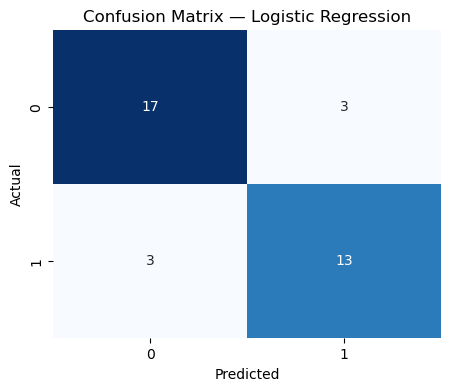


SVM
Confusion matrix:
[[ 9 11]
 [ 0 16]]
              precision    recall  f1-score   support

  No disease       1.00      0.45      0.62        20
     Disease       0.59      1.00      0.74        16

    accuracy                           0.69        36
   macro avg       0.80      0.72      0.68        36
weighted avg       0.82      0.69      0.68        36



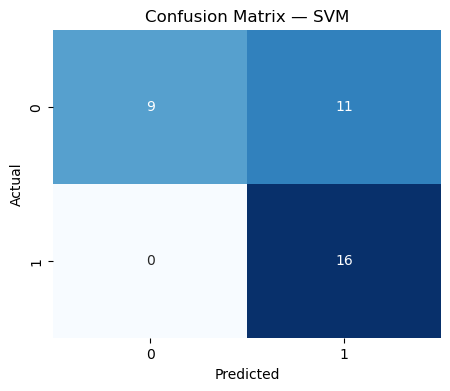


Random Forest
Confusion matrix:
[[16  4]
 [ 1 15]]
              precision    recall  f1-score   support

  No disease       0.94      0.80      0.86        20
     Disease       0.79      0.94      0.86        16

    accuracy                           0.86        36
   macro avg       0.87      0.87      0.86        36
weighted avg       0.87      0.86      0.86        36



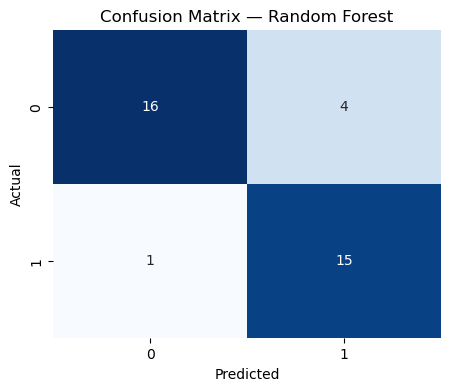

In [96]:

for name, fitted in models.items():
    pred = fitted.predict(X_test)
    cm = confusion_matrix(y_test, pred)
    print(f"\n{name}")
    print("Confusion matrix:")
    print(cm)
    print(classification_report(y_test, pred, target_names=["No disease", "Disease"], zero_division=0))
    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Confusion Matrix — {name}")
    plt.show()

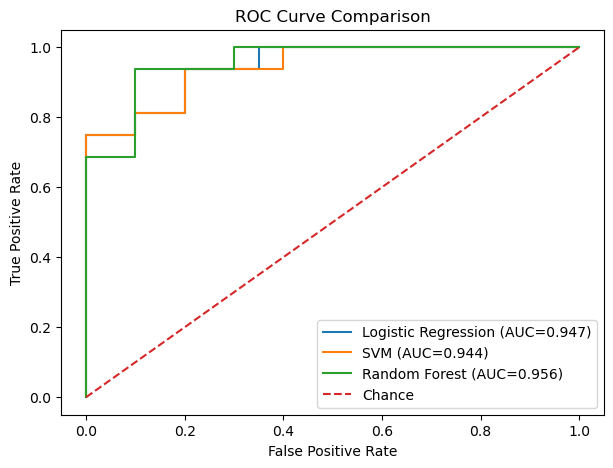

In [98]:
plt.figure(figsize=(7,5))
for name, prob in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, prob):.3f})")
plt.plot([0,1], [0,1], "--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()


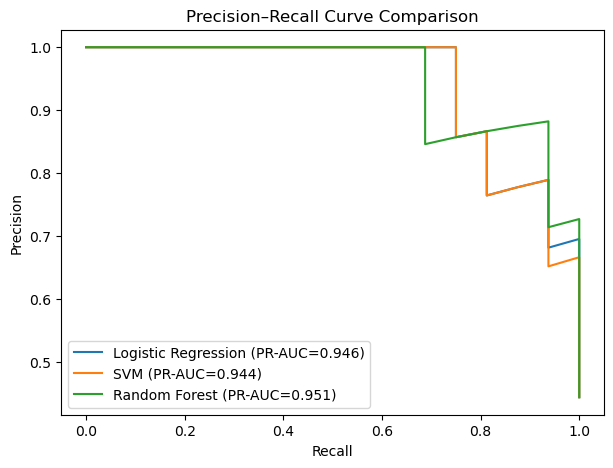

In [100]:

plt.figure(figsize=(7,5))
for name, prob in probabilities.items():
    precision, recall, _ = precision_recall_curve(y_test, prob)
    plt.plot(recall, precision, label=f"{name} (PR-AUC={average_precision_score(y_test, prob):.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve Comparison")
plt.legend()
plt.show()

## 11. Threshold optimization on validation data only
The default 0.50 threshold is not automatically optimal for screening. We choose a threshold using **F2-score**, which weights recall more heavily than precision. The test set remains untouched during this selection.

In [103]:
from sklearn.metrics import fbeta_score
best_name = results_df.iloc[0]["Model"]
best_model = models[best_name]
valid_prob = best_model.predict_proba(X_valid)[:, 1]
threshold_grid = np.linspace(0.10, 0.90, 161)
threshold_scores = [(t, fbeta_score(y_valid, (valid_prob >= t).astype(int), beta=2, zero_division=0)) for t in threshold_grid]
best_threshold, best_f2 = max(threshold_scores, key=lambda z: z[1])
print(f"Selected model: {best_name}")
print(f"Validation-selected threshold: {best_threshold:.3f}")
print(f"Validation F2 at selected threshold: {best_f2:.4f}")

Selected model: Random Forest
Validation-selected threshold: 0.225
Validation F2 at selected threshold: 0.8427


In [105]:

test_prob = best_model.predict_proba(X_test)[:, 1]
test_threshold_pred = (test_prob >= best_threshold).astype(int)
threshold_cm = confusion_matrix(y_test, test_threshold_pred)
threshold_metrics = {
    "Accuracy": accuracy_score(y_test, test_threshold_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_test, test_threshold_pred),
    "Precision": precision_score(y_test, test_threshold_pred, zero_division=0),
    "Recall": recall_score(y_test, test_threshold_pred, zero_division=0),
    "F1": f1_score(y_test, test_threshold_pred, zero_division=0),
    "F2": fbeta_score(y_test, test_threshold_pred, beta=2, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_prob),
    "PR-AUC": average_precision_score(y_test, test_prob)
}
print(pd.Series(threshold_metrics).round(4).to_string())
print("\nThreshold-adjusted confusion matrix:")
print(threshold_cm)
print(f"\nModel weakness check: {threshold_cm[1,0]} disease cases were missed and {threshold_cm[0,1]} healthy cases were flagged at the selected threshold.")

Accuracy             0.6667
Balanced Accuracy    0.7000
Precision            0.5714
Recall               1.0000
F1                   0.7273
F2                   0.8696
ROC-AUC              0.9562
PR-AUC               0.9505

Threshold-adjusted confusion matrix:
[[ 8 12]
 [ 0 16]]

Model weakness check: 0 disease cases were missed and 12 healthy cases were flagged at the selected threshold.


## 12. Model Comparison

The models are compared using multiple evaluation metrics rather than accuracy alone. For a heart-disease screening task, Recall is especially important because false negatives represent patients with disease who may be missed. ROC-AUC and PR-AUC assess ranking/discrimination, while F1 balances precision and recall.

The table below uses the actual test-set results generated by the notebook, so no performance values are hard-coded. The selected model is based on ROC-AUC, with PR-AUC and F1 used as tie-breakers.

In [108]:

comparison = results_df.copy()

print("MODEL COMPARISON")
print("=" * 70)
display(comparison.round(4))

print(f"Selected model: {best_name}")
print(
    f"Reason: highest ROC-AUC, with PR-AUC and F1 used as tie-breakers. "
    f"Recall is also reviewed because missed disease cases are clinically important."
)
for _, r in comparison.iterrows():
    print(
        f"{r['Model']}: Recall={r['Recall']:.3f}, "
        f"Precision={r['Precision']:.3f}, F1={r['F1']:.3f}, "
        f"ROC-AUC={r['ROC-AUC']:.3f}, PR-AUC={r['PR-AUC']:.3f}"
    )

MODEL COMPARISON


,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Random Forest,0.8611,0.8688,0.7895,0.9375,0.8571,0.9562,0.9505
1,Logistic Regression,0.8333,0.8312,0.8125,0.8125,0.8125,0.9469,0.9456
2,SVM,0.6944,0.7250,0.5926,1.0000,0.7442,0.9438,0.9438


Selected model: Random Forest
Reason: highest ROC-AUC, with PR-AUC and F1 used as tie-breakers. Recall is also reviewed because missed disease cases are clinically important.
Random Forest: Recall=0.938, Precision=0.789, F1=0.857, ROC-AUC=0.956, PR-AUC=0.951
Logistic Regression: Recall=0.812, Precision=0.812, F1=0.812, ROC-AUC=0.947, PR-AUC=0.946
SVM: Recall=1.000, Precision=0.593, F1=0.744, ROC-AUC=0.944, PR-AUC=0.944


## 13. Challenges Faced

### 1. Class imbalance
The target classes were checked before modeling. Accuracy alone can be misleading when the classes are not evenly represented, so balanced accuracy, Recall, F1, ROC-AUC and PR-AUC were also evaluated.

### 2. Missing values and data quality
Missing values were identified during EDA and handled inside preprocessing pipelines. This prevents test-set information from influencing the training transformations.

### 3. Outliers
Medical measurements can contain genuine extreme values. Instead of automatically deleting observations, outliers were diagnosed and retained unless there was a defensible data-quality reason to remove them.

### 4. Multicollinearity
Highly correlated numerical predictors can add redundancy and make linear models harder to interpret. Correlation analysis was performed and redundant predictors were considered during the training-stage preprocessing.

### 5. Data leakage
Imputation, encoding and scaling were fitted through training-only pipelines. The held-out test set was kept separate until final evaluation.

### 6. Model selection and tuning
Different algorithms can capture different relationships in the data. Logistic Regression, SVM and Random Forest were tuned using stratified cross-validation instead of relying only on default parameters.

### 7. Classification threshold
A 0.50 probability threshold is not necessarily appropriate for screening. The final threshold was selected using the validation set and F2-score to place greater emphasis on Recall, while the test set remained untouched during threshold selection.

### 8. Model weaknesses and interpretability
A model should not be judged only by one score. Confusion matrices, precision, recall, F1, ROC-AUC and PR-AUC were reviewed to understand false positives and false negatives. Feature importance/coefficient analysis was also used to improve interpretability.

### 9. Generalization
Good test performance does not guarantee safe real-world performance. External/temporal validation, probability calibration, subgroup evaluation and monitoring would be needed before practical clinical deployment.

## 14. Feature importance / interpretability
The final model's transformed feature names are displayed with their importance or absolute coefficient magnitude. This helps connect predictions to clinically interpretable inputs, while remembering that association is not causation.

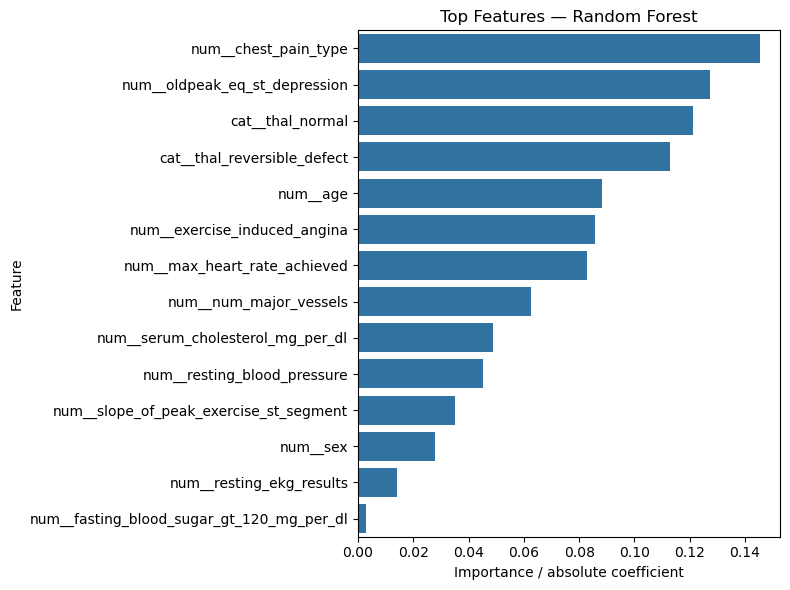

In [112]:
prep = best_model.named_steps["prep"]
transformed_names = prep.get_feature_names_out()
model_step = best_model.named_steps["model"]
if hasattr(model_step, "feature_importances_"):
    importance_values = model_step.feature_importances_
else:
    importance_values = np.abs(model_step.coef_[0])
importance_df = pd.DataFrame({"feature": transformed_names, "importance": importance_values}).sort_values("importance", ascending=False).head(15)
plt.figure(figsize=(8,6))
sns.barplot(data=importance_df, x="importance", y="feature")
plt.title(f"Top Features — {best_name}")
plt.xlabel("Importance / absolute coefficient")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 15. Final model conclusion
The final recommendation below is generated from the executed results rather than hard-coded metrics.

In [115]:
best_row = results_df.iloc[0]
print(f"Best model by ROC-AUC (then PR-AUC and F1): {best_name}")
print(f"ROC-AUC={best_row['ROC-AUC']:.3f}, PR-AUC={best_row['PR-AUC']:.3f}, Recall={best_row['Recall']:.3f}, F1={best_row['F1']:.3f}")
print(f"The validation-selected F2 threshold is {best_threshold:.3f}, prioritizing recall for screening.")

Best model by ROC-AUC (then PR-AUC and F1): Random Forest
ROC-AUC=0.956, PR-AUC=0.951, Recall=0.938, F1=0.857
The validation-selected F2 threshold is 0.225, prioritizing recall for screening.


## 16. Example prediction helper
The helper below uses the **same fitted preprocessing pipeline and selected threshold** as the final model, avoiding manual one-hot encoding mismatches.

In [118]:
def predict_heart_disease(patient_dict):
    row = pd.DataFrame([patient_dict])
    probability = best_model.predict_proba(row)[:, 1][0]
    prediction = int(probability >= best_threshold)
    label = "HIGHER HEART-DISEASE RISK" if prediction == 1 else "LOWER HEART-DISEASE RISK"
    return {"prediction": prediction, "probability": probability, "label": label, "threshold": best_threshold}
example_patient = {
    "slope_of_peak_exercise_st_segment": 1, "resting_blood_pressure": 120, "chest_pain_type": 2,
    "num_major_vessels": 0, "fasting_blood_sugar_gt_120_mg_per_dl": 0, "resting_ekg_results": 0,
    "serum_cholesterol_mg_per_dl": 180, "oldpeak_eq_st_depression": 0.0, "sex": 0, "age": 35,
    "max_heart_rate_achieved": 175, "exercise_induced_angina": 0, "thal": "normal"
}
print(predict_heart_disease(example_patient))

{'prediction': 0, 'probability': 0.04266979485442549, 'label': 'LOWER HEART-DISEASE RISK', 'threshold': 0.225}


## Final takeaway
This version treats the notebook as an end-to-end classification project: **EDA → data-quality decisions → leakage-safe preprocessing → multicollinearity control → tuned cross-validation → test evaluation → threshold selection → interpretation → business/clinical next steps**.

Run the notebook from the beginning after placing `values.csv` and `labels.csv` in the expected location. The metrics and conclusions are intentionally generated dynamically from the executed data.